/home/cpz/anaconda3/envs/rl4co/lib/python3.12/site-packages/torchrl/data/replay_buffers/samplers.py:37: UserWarning: Failed to import torchrl C++ binaries. Some modules (eg, prioritized replay buffers) may not work with your installation. If you installed TorchRL from PyPI, please report the bug on TorchRL github. If you installed TorchRL locally and/or in development mode, check that you have all the required compiling packages.
  warnings.warn(EXTENSION_WARNING)
/home/cpz/anaconda3/envs/rl4co/lib/python3.12/site-packages/lightning_utilities/core/imports.py:13: DeprecationWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html
  import pkg_resources
/home/cpz/anaconda3/envs/rl4co/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/home/cpz/anaconda3/envs

Problem 1 | Cost: 8.258
Problem 2 | Cost: 7.362
Problem 3 | Cost: 8.204


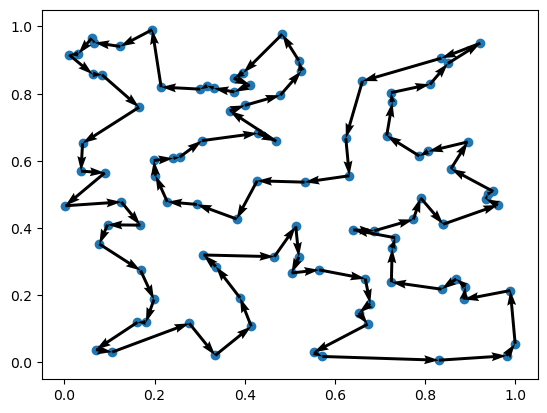

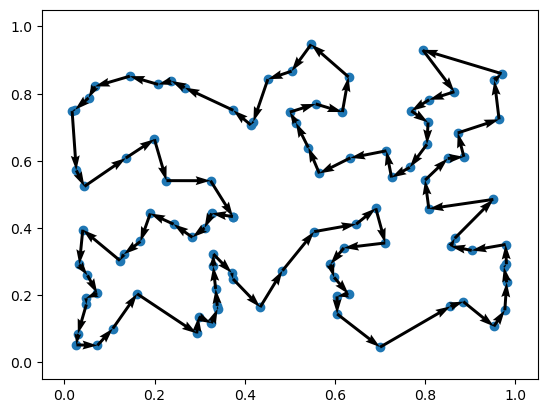

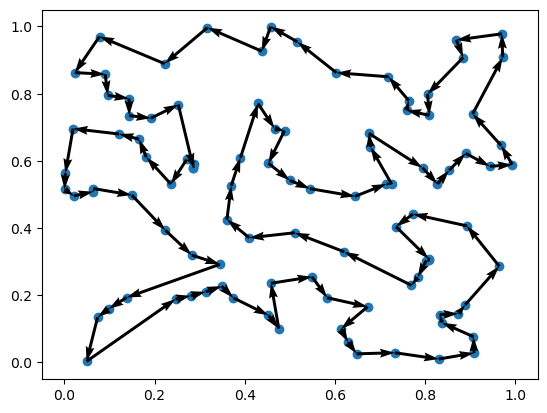

In [1]:
from rl4co.envs import get_env

from rl4co.models.zoo import POMO, SymNCO, NARGNNPolicy
from rl4co.models.zoo.am.decoder import AttentionModelDecoder
from rl4co.models.nn.attention import PolyNetAttention
from models.zoo.icam.encoder import ICAMEncoder
from models.zoo.icam.decoder import ICAMDecoder

import os
import torch
import lightning as L
from rl4co.utils.ops import gather_by_index, unbatchify

L.seed_everything(1234)

num_loc = 100
save_dir = "./lightning_logs/"
env_name = "tsp"
name = f"pomo_{env_name}{num_loc}_poly_cab"
env = get_env(env_name=env_name, generator_params=dict(num_loc=num_loc), check_solution=False)

pointer = PolyNetAttention(
    k=num_loc, 
    embed_dim=128, 
    poly_layer_dim=256,
    num_heads=8,
)

icam_encoder = ICAMEncoder(
    env_name=env_name,
    embed_dim=128,
    num_layers=6,
    normalization="instance",
)

icam_poly_decoder = ICAMDecoder(
    env_name=env_name,
    pointer=pointer,
)

model = POMO(
    env, 
    train_data_size=160_000,
    val_data_size=10_000,
    batch_size=64,
    val_batch_size=500,
    num_augment=8,
    # policy=NARGNNPolicy(),
    policy_kwargs={
        "val_decode_type": "greedy",
        "test_decode_type": "greedy",
        "encoder": icam_encoder,
        "decoder": icam_poly_decoder,
        "tanh_clipping": 50.,
    },
)

model = model.load_from_checkpoint('lightning_logs/checkpoints/pomo_tsp100_aft_poly_cab/last.ckpt')

device = "cpu"
n_samples = 3
td_init = env.reset(batch_size=[n_samples]).to(device)
policy = model.policy.to(device)

out = policy(td_init.clone(), phase="test", decode_type="greedy", return_actions=True)
actions = out['actions'].cpu().detach()
rewards = out['reward'].cpu().detach()

for i in range(3):
    print(f"Problem {i+1} | Cost: {-rewards[i]:.3f}")
    env.render(td_init[i], actions[i])

Problem 1 | Improved Cost: 8.245
Problem 2 | Improved Cost: 7.348
Problem 3 | Improved Cost: 8.166


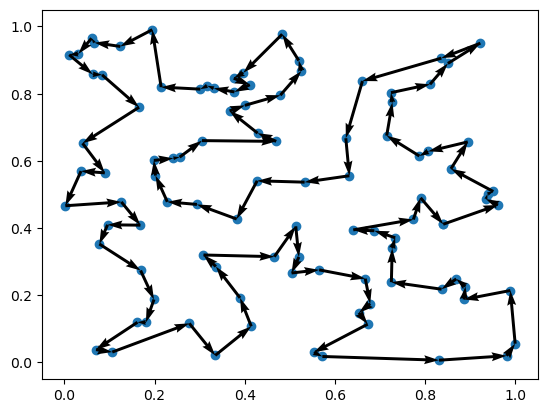

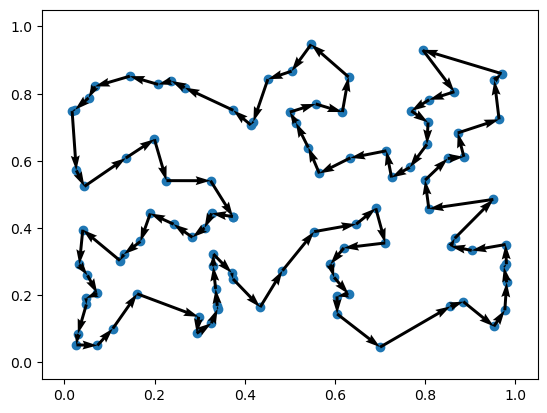

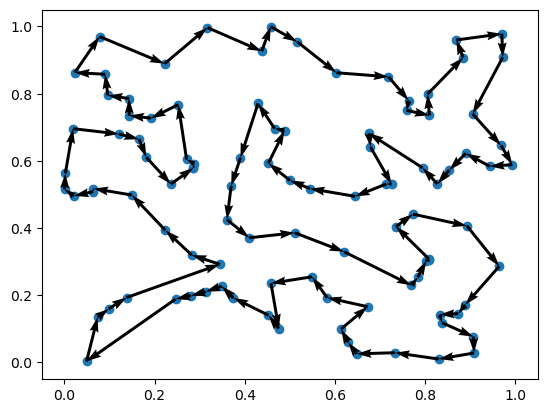

In [2]:
improved_actions = env.local_search(td_init, actions)
improved_rewards = env.get_reward(td_init, improved_actions)

for i in range(3):
    print(f"Problem {i+1} | Improved Cost: {-improved_rewards[i]:.3f}")
    env.render(td_init[i], improved_actions[i])